In [1]:
import numpy as np
import matplotlib.pyplot as plt

from som_rl.som.som_backend import SharpZSOMBackend, SharpZBackendConfig
from som_rl.env.schedules import SchedulerConfig, FixedScheduler, HitGatedScheduler, PlateauGatedScheduler
from som_rl.env.env import (
    SOMEnergyEnvConfig,
    EnvTeleportNodeRandomBin,
)

from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy, plot_results
from stable_baselines3.common.callbacks import CheckpointCallback, EvalCallback, StopTrainingOnNoModelImprovement
from stable_baselines3.common.logger import configure
from stable_baselines3.common.vec_env import DummyVecEnv

import gymnasium as gym
from gymnasium.envs.registration import register
from gymnasium.spaces import Box, Discrete



In [2]:
import torch

print("torch version:", torch.__version__)
print("mps available:", torch.backends.mps.is_available())
print("mps built:", torch.backends.mps.is_built())
print("default device:", torch.device("mps" if torch.backends.mps.is_available() else "cpu"))

torch version: 2.10.0
mps available: True
mps built: True
default device: mps


In [3]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
x = torch.randn(1024, 1024, device=device)
y = x @ x
print("tensor device:", y.device)

tensor device: mps:0


In [4]:
# Dumb env
env = gym.make("CartPole-v1")
# vecotorise env


In [5]:
model = PPO("MlpPolicy", env, device="mps")  # or "cpu"
print("SB3 device:", model.device)

SB3 device: mps


/Users/james/opt/anaconda3/envs/sharp-rl-arm/lib/python3.10/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


In [6]:
next(model.policy.parameters()).device

device(type='mps', index=0)

In [7]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
model = PPO("MlpPolicy", env, device=device)

In [8]:
del model
del env
del x
del y

In [9]:
# Load data (from 08-Updated_Env_Tests.ipynb)
DATA = "data"  # adjust

npz = np.load(f"{DATA}/correlations_dl/npairs_compact.npz")
dd, dr, rd, rr = npz["dd"], npz["dr"], npz["rd"], npz["rr"]

node_indices_photo = np.load(f"{DATA}/node_indices_fc.npy")  # (Nphot,)
initial_node_bins  = np.load(f"{DATA}/nodes_labels_initial_fc_200_ext.npy")  # (40000,)
reference_labels   = np.load(f"{DATA}/reference_labels_fc_fc.npy")  # (Nref,) in [0..10]

weighted_clusters  = np.load(f"{DATA}/weighted_clusters_5c_1t200.npy")  # (L,40000)

# umatrix: if you already extracted it from the pickled somoclu object, load it.
# If not, set to None for now.
umatrix = np.load(f"{DATA}/umat.npy")  # (200,200)


In [10]:
# Build backend(s)

b_cfg = SharpZBackendConfig(
    grid_shape=(200, 200),
    num_bins=11,
    objective_mode="energy",
    proposal_bin_mode="uniform_other",
)

def make_backend():
    return SharpZSOMBackend(
        cfg=b_cfg,
        dd=dd, dr=dr, rd=rd, rr=rr,
        node_indices_photo=node_indices_photo,
        initial_node_bins=initial_node_bins,
        reference_labels=reference_labels,
        umatrix=umatrix,
        weighted_clusters=weighted_clusters,
    )

som_rl = make_backend()
som_rand = make_backend()

print("E0 RL:", som_rl.energy_E())
print("E0 random:", som_rand.energy_E())


E0 RL: 0.023775093565945846
E0 random: 0.023775093565945846


In [11]:
# Custom scheduler: hit-gated over discrete levels [30, 50, 80]

class HitListScheduler:
    def __init__(self, *, levels, hits_per_level, T=1.0, floor=1e-5):
        self.levels = list(levels)
        self.hits_per_level = int(hits_per_level)
        self.T = float(T)
        self.floor = float(floor)
        self.reset()

    def reset(self):
        self.step_idx = 0
        self.level_idx = 0
        self.level = int(self.levels[self.level_idx])
        self._acc = 0

    def current_params(self):
        return int(self.level), float(self.T), float(self.floor)

    def update(self, *, accepted: bool, dE: float, E: float, step_idx: int | None = None, is_noop: bool = False):
        if accepted and (not is_noop):
            self._acc += 1
        if self._acc >= self.hits_per_level:
            self._acc = 0
            if self.level_idx < len(self.levels) - 1:
                self.level_idx += 1
                self.level = int(self.levels[self.level_idx])
        if step_idx is None:
            step_idx = self.step_idx
        self.step_idx = int(step_idx) + 1


In [12]:
# Build envs (same constraints) for PPO and random baseline

levels = [30, 50, 80]
HITS_PER_LEVEL = 200

env_cfg = SOMEnergyEnvConfig(
    grid_shape=(200, 200),
    obs_mode="global",          # use full map for diagnostics
    patch_size=9,
    include_umatrix=True,
    include_cluster_features=True,
    include_empty_mask=True,
    include_visit_count=True,
    include_recent_mask=True,
    recent_cooldown_steps=10,
    max_steps=2000,
    initial_level=levels[0],
    initial_temperature=1.0,
    
)

scheduler_rl = HitListScheduler(levels=levels, hits_per_level=HITS_PER_LEVEL, T=1.0, floor=1e-5)
scheduler_rand = HitListScheduler(levels=levels, hits_per_level=HITS_PER_LEVEL, T=1.0, floor=1e-5)

env_rl = EnvTeleportNodeRandomBin(som_rl, env_cfg, scheduler=scheduler_rl)
env_rand = EnvTeleportNodeRandomBin(som_rand, env_cfg, scheduler=scheduler_rand)

# Optional: sanity check
# check_env(env_rl, warn=True)


In [13]:
# Train PPO (use MultiInputPolicy because obs is a dict)

vec_env = DummyVecEnv([lambda: Monitor(env_rl)])

model = PPO(
    "MultiInputPolicy",
    vec_env,
    device="mps" if torch.backends.mps.is_available() else "cpu",
    verbose=1,
    clip_reward=[-1,1]
)

# Quick train (increase as needed)
model.learn(total_timesteps=200_000)


Using mps device
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 2e+03    |
|    ep_rew_mean     | 1.95e+08 |
| time/              |          |
|    fps             | 118      |
|    iterations      | 1        |
|    time_elapsed    | 17       |
|    total_timesteps | 2048     |
---------------------------------
---------------------------------------
| rollout/                |           |
|    ep_len_mean          | 2e+03     |
|    ep_rew_mean          | 1.95e+08  |
| time/                   |           |
|    fps                  | 87        |
|    iterations           | 2         |
|    time_elapsed         | 46        |
|    total_timesteps      | 4096      |
| train/                  |           |
|    approx_kl            | 0.0       |
|    clip_fraction        | 0         |
|    clip_range           | 0.2       |
|    entropy_loss         | -10.6     |
|    explained_variance   | 1.19e-07  |
|    learning_rate        | 0.0003    |
|  

In [14]:
# Evaluate PPO vs random baseline

def run_episode(env, policy_fn, seed=0):
    obs, info = env.reset(seed=seed)
    total_reward = 0.0
    terminated = False
    truncated = False
    steps = 0

    while not (terminated or truncated):
        action = policy_fn(obs)
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += float(reward)
        steps += 1

    final_energy = float(info.get("E1", env.som.energy_E()))
    return total_reward, final_energy, steps


def eval_random(env, n_episodes=3, seed=0):
    rewards, energies, steps = [], [], []
    for ep in range(n_episodes):
        r, e, s = run_episode(env, lambda _obs: env.action_space.sample(), seed=seed + ep)
        rewards.append(r); energies.append(e); steps.append(s)
    return rewards, energies, steps


def eval_ppo(env, model, n_episodes=3, seed=0):
    rewards, energies, steps = [], [], []
    for ep in range(n_episodes):
        r, e, s = run_episode(env, lambda _obs: model.predict(_obs, deterministic=True)[0], seed=seed + ep)
        rewards.append(r); energies.append(e); steps.append(s)
    return rewards, energies, steps


rand_rewards, rand_energies, rand_steps = eval_random(env_rand, n_episodes=3, seed=0)
ppo_rewards, ppo_energies, ppo_steps = eval_ppo(env_rl, model, n_episodes=3, seed=0)

print("Random: mean reward", np.mean(rand_rewards), "mean final E", np.mean(rand_energies))
print("PPO:    mean reward", np.mean(ppo_rewards), "mean final E", np.mean(ppo_energies))


Random: mean reward 194265425.98390365 mean final E 0.02955796738478639
PPO:    mean reward 199932173.13360643 mean final E 0.02389815785836397


In [15]:
def get_actions(env, policy_fn, seed=0):
    obs, info = env.reset(seed=seed)
    total_reward = 0.0
    terminated = False
    truncated = False
    steps = 0
    actions = []

    while not (terminated or truncated):
        action = policy_fn(obs)
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += float(reward)
        steps += 1
        actions.append(action)
    final_energy = float(info.get("E1", env.som.energy_E()))
    return total_reward, final_energy, steps, actions

_, _, _, actions = get_actions(env_rl, lambda _obs: env_rl.action_space.sample())

# print actions made by model
print(actions)
# convert actions with index 0 to 40,000 to an x,y coordinate
actions_coords = np.unravel_index(actions, (200, 200))
# get pairs of x,y coordinates
actions_coords_pairs = list(zip(actions_coords[0], actions_coords[1]))
# print pairs
print(actions_coords_pairs)
# convert to numpy array
actions_coords_pairs = np.array(actions_coords_pairs)
# print shape
print(actions_coords_pairs.shape)
# convert to a 2D array of shape 200x200 where the value is the number of times the action was taken
actions_coords_pairs_count = np.zeros((200, 200))
for i in range(actions_coords_pairs.shape[0]):
    actions_coords_pairs_count[actions_coords_pairs[i][0], actions_coords_pairs[i][1]] += 1
    


[29670, 7698, 19018, 2254, 5294, 33876, 30947, 20441, 27002, 12967, 5972, 28889, 34833, 7177, 12773, 30478, 18125, 39975, 17625, 21784, 8358, 39832, 27937, 32059, 5122, 20125, 11151, 26760, 37949, 5950, 4935, 35942, 29145, 9560, 17614, 6707, 32738, 4647, 3123, 35994, 25960, 21069, 5569, 15124, 157, 21003, 6602, 11178, 18615, 32823, 26408, 1818, 11216, 38068, 3768, 36241, 17286, 22827, 25078, 38955, 22388, 39795, 17279, 15541, 14830, 24531, 9593, 17221, 13214, 25023, 16037, 16161, 752, 16827, 22011, 21165, 22991, 28918, 38766, 28821, 24545, 6982, 11162, 5683, 18529, 1911, 14624, 12799, 4933, 20550, 38472, 18882, 8205, 7851, 26058, 10099, 9401, 20437, 5488, 21254, 8199, 39476, 38863, 1078, 39097, 3007, 32494, 20192, 1975, 5810, 32581, 7295, 31151, 5649, 22103, 7750, 10109, 32048, 8930, 25207, 6912, 18449, 34922, 38366, 7545, 10342, 35574, 15712, 28455, 15304, 16080, 21013, 8137, 109, 1560, 32950, 23824, 11247, 25038, 25119, 16544, 9084, 642, 9064, 7347, 29734, 22151, 35390, 36543, 9853, 

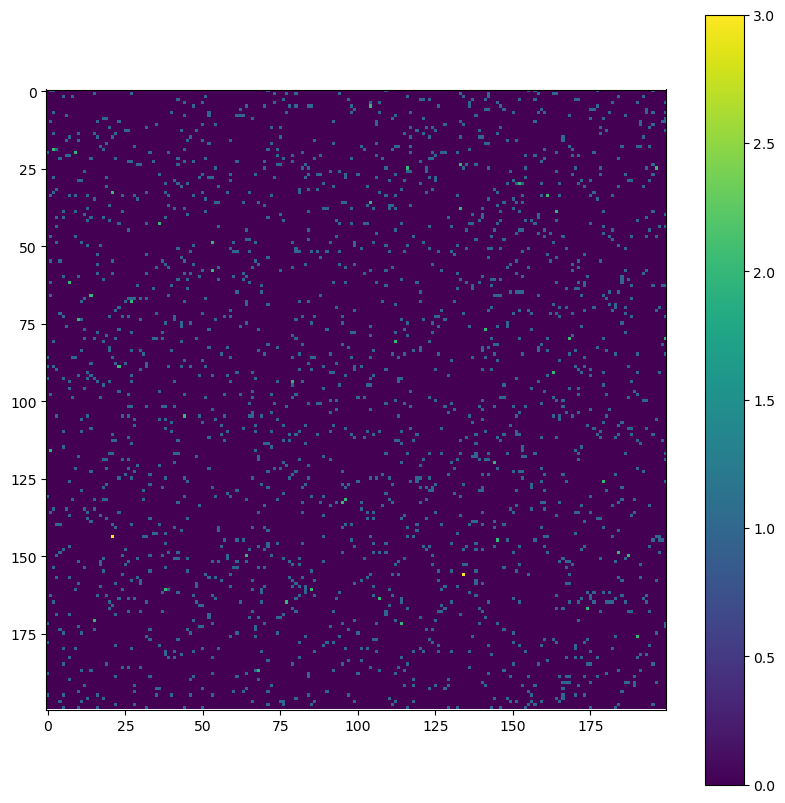

In [16]:
# Plot the actions on 200x200 grid with heatmap
plt.figure(figsize=(10, 10))
plt.imshow(actions_coords_pairs_count, cmap="viridis")
plt.colorbar()
plt.show()

In [17]:
# Let's use the eval code
from som_rl.eval.rollout import run_episode
from som_rl.eval.plots import plot_trace, plot_delta_hist, plot_noop_rate_ma, plot_heatmaps, plot_bin_snapshots, save_all_plots
from som_rl.eval.ideal_som import get_perfect_bins, plot_bins_triptych